# *Chlorella vulgaris* phenotypes are structured and predictable across environmental conditions

Analysis notebook for the pub. Running it top to bottom reproduces every quantitative result and data figure in the pub, followed by the supplemental analyses that support methodological choices.

**How to run**

1. Put this folder next to the data: by default it expects `../zarrs/` and `../jsonls/` (set `DATA_DIR` below otherwise).
2. Install the requirements (`pip install -r requirements.txt`).
3. Check the **Parameters** cell, then *Run All*. Figures go to `plots/`, tables to `results/`.

All functions live in `cvp_pub.py` (imported as `cvpp`). Its header lists which function computes each result, so you can check the math directly.

**Contents**

| § | Pub section | Figure / result |
|---|---|---|
| 1 | Load data | dead-well filter, FoV-level feature matrices, Hu log transform |
| 2 | Mutagenesis generates diverse phenotypes | example images; *Heatmap of normalized features for all strains*; *Mutants are more phenotypically diverse than wild-type isolates* |
| 3 | Reliable features organize phenotypic variation | *Reliable features…* A (ICC), B–E (t-SNE) |
| 4 | The environment observably modulates phenotypes | *Environment observably modulates phenotypes* A (images), B (PCA trajectories) |
| 5 | Phenotypes are predictable in held-out environments | *Schematic*; *Model performance* A–D |
| 6 | Predictability arises from structured variance | *Structured variance explains model performance* A–C |
| 7 | Strain departures (37 vs 94) | *Phenotypic interaction structure beyond strain identity* A–B |
| S1 | Supplemental | ridge alpha scan |
| S2 | Supplemental | strain identity (one confusion matrix per condition) |
| S3 | Supplemental | interaction structure beyond strain identity (automatic example pairs) |
| S4 | Supplemental | batch effects (plate position, cross-condition gradients, WT batch correction) |
| S5 | Supplemental | correlation between features |

## Parameters
Everything you might want to change is in this cell.

In [53]:
# ---------------- paths ----------------
DATA_DIR = ".."                       # folder that contains zarrs/ and jsonls/
PLOT_DIR = "plots"                    # figures (cvp_pub functions write to ./plots)
RESULTS_DIR = "results"               # tables / numbers quoted in the text
CACHE_PATH = "results/feature_matrices_cache.npz"   # FoV-level feature matrices (skip the slow load)
USE_CACHE = True                      # load matrices from CACHE_PATH if it exists; images still need the zarrs

# ---------------- experiments ----------------
# condition key -> experiment batch id (zarrs/experiment_batches_<id>_features.zarr)
EXPERIMENT_IDS = {
    "e_stat_16": "20260105_203447_582",   # early stationary, 16 °C
    "e_stat_22": "20260105_125955_886",   # early stationary, 22 °C
    "e_stat_30": "20260105_161353_802",   # early stationary, 30 °C
    "l_stat_16": "20260112_161051_665",   # late stationary, 16 °C
    "l_stat_22": "20260112_112101_320",   # late stationary, 22 °C
    "l_stat_30": "20260112_135035_609",   # late stationary, 30 °C
}
WT_EXPERIMENT_ID = "20251209_091846_235"  # wild-type isolates, early stationary, 22 °C
CONDITION_TITLES = ["16C e.stat", "22C e.stat", "30C e.stat", "16C l.stat", "22C l.stat", "30C l.stat"]

# ---------------- feature extraction / QC ----------------
N_WELLS = 96
N_FOVS = 9                            # fields of view analyzed per well
CELL_COUNT_CUTOFF = 50                # a well is dead if any condition/FoV/channel has fewer cells
EXCLUDE_FEATURES = ["moments_hu-4", "moments_hu-5", "moments_hu-6"]   # dominated by imaging artifacts
CHANNELS = ("BF", "CY5")
HU_LOG_EPS = 1e-12                    # signed log10 transform: sign(H) * log10(|H| + eps)

# ---------------- feature heatmap (§2) ----------------
HEATMAP_TEMPERATURE = 22              # NOTE: pub caption says 22 °C; the figure in the draft was made with 30
HEATMAP_GROWTH_STAGE = "e_stat"
HEATMAP_VLIM = 5

# ---------------- reliability / embeddings (§3–4) ----------------
ICC_N_PERMUTATIONS = 500              # permutation test across wells (min p = 1/(n+1) ≈ 0.002)
ICC_SPLIT_HALF_REPEATS = 100
ICC_RELIABLE_THRESHOLD = 0.5          # "reliable features" = mean ICC >= this (PCA trajectories)
TSNE_PERPLEXITY = 50
TSNE_RANDOM_STATE = 28
TSNE_USE_HU_LOG = True                # False reproduces the draft figure (t-SNE was run before the Hu log transform)
TSNE_COLOR_FEATURES = ["area (bf)", "moments_hu-0 (bf)", "orientation (bf)"]   # or "all"
TRAJ_STRAINS = [10, 12, 27]
TRAJ_CONDITIONS = ["e_stat_16", "e_stat_22", "e_stat_30"]
TRAJ_CONDITION_LABELS = ["e.16C", "e.22C", "e.30C"]
TRAJ_PCA_CONDITIONS = ["e_stat_16", "e_stat_22", "e_stat_30"]   # conditions used to z-score + fit the PCA
EXAMPLE_IMAGE_STRAINS = [12, 27, 10]   # "Mutagenized Chlorella" B–D (30 °C, early stationary)
EXAMPLE_IMAGE_FOV = 0
EXAMPLE_IMAGE_CROP = 300              # pixels

# ---------------- predictive model (§5–7) ----------------
RIDGE_ALPHA = 3000
N_CV_SPLITS = 16                      # GroupKFold by well
RANDOM_STATE = 28
DEPARTURE_STRAINS = [37, 94]
DEPARTURE_CONDITIONS = ["l_stat_16", "l_stat_22", "l_stat_30"]
DEPARTURE_CONDITION_LABELS = ["16 °C", "22 °C", "30 °C"]
DEPARTURE_FEATURES = ["count (bf)", "eccentricity (bf)", "area (bf)"]
FDR_Q = 0.05

# ---------------- supplemental ----------------
RUN_SUPPLEMENTAL = {
    "alpha_scan": True,               # S1 (slow: 16 alphas x 6 held-out conditions)
    "strain_identity": True,          # S2
    "interaction_examples": True,     # S3
    "batch_effects": True,            # S4
    "feature_correlations": True,     # S5 (cell-level version reads every cell from the JSONL)
}
ALPHA_SCAN_ALPHAS = [2 ** k for k in range(1, 17)]
ALPHA_SCAN_GROUPED = False            # False = original scan (shuffled KFold); True = GroupKFold by well like the final model
INTERACTION_FEATURE = "count (bf)"
INTERACTION_CONDITIONS = ["l_stat_16", "l_stat_22", "l_stat_30"]
INTERACTION_APART_MIN, INTERACTION_TOGETHER_MAX, INTERACTION_MIN_SNR = 1, 0.2, 3
PLATE_ROWS, PLATE_COLS, PLATE_LAYOUT = 8, 12, "row_major"
PLATE_HEATMAP_CONDITION, PLATE_HEATMAP_FEATURE_INDEX = "e_stat_30", 0
GRADIENT_N_NULL = 1000
WT_GRADIENT_N_NULL = 2000                # shuffles of the WT plate for the position-only null (S4); min p = 1/(n+1) ≈ 0.001 (~5 min)
WT_GRADIENT_PLATE_FEATURE = "count (bf)"   # feature drawn on the WT vs mutant plate maps (S4)
FEATURE_CORR_MAX_CELLS_PER_WELL = 200

## Setup

In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arcadia_pycolor as apc

import cvp_pub as cvpp

apc.mpl.setup()
apc.plotly.setup()

for d in (PLOT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

EXP_CONDITIONS = list(EXPERIMENT_IDS)
CONDITION_COLORS = [apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy]
COND_COLOR = dict(zip(EXP_CONDITIONS, CONDITION_COLORS))
COND_TITLE = dict(zip(EXP_CONDITIONS, CONDITION_TITLES))

def zarr_path(exp_id):
    return os.path.join(DATA_DIR, "zarrs", f"experiment_batches_{exp_id}_features.zarr")

def jsonl_path(exp_id):
    return os.path.join(DATA_DIR, "jsonls", f"experiment_batches_{exp_id}_features.jsonl")

def save_table(df, name, **kw):
    """Write a results table to RESULTS_DIR and return it for display."""
    df.to_csv(os.path.join(RESULTS_DIR, name), **kw)
    return df

## 1 · Load data

Each condition becomes a matrix with one row per (well, field of view) and one column per feature (20 per channel: 19 Cellpose features + mean pixel intensity). Rows are FoV-major (`row = well + fov * N_WELLS`). A field's value is the mean across its segmented cells.

* **Dead wells:** a well is excluded everywhere if any condition, FoV, or channel has fewer than `CELL_COUNT_CUTOFF` cells.
* **Missing values** (e.g. an empty channel in one field) are filled with the condition's feature mean.
* **Hu moments** get a signed log10 transform before any statistics.

Loading reads the JSONL feature files (a few minutes). The matrices are cached to `CACHE_PATH`; the image panels still need the zarrs.

In [3]:
# Experiment stores (lazy; nothing heavy is read until a function asks for it)
zroots = [cvpp.ExperimentStore(zarr_path(EXPERIMENT_IDS[c]), jsonl_path(EXPERIMENT_IDS[c]))
          for c in EXP_CONDITIONS]

if USE_CACHE and os.path.exists(CACHE_PATH):
    cache = np.load(CACHE_PATH, allow_pickle=True)
    training_data = {c: cache[f"td_{c}"] for c in EXP_CONDITIONS}
    training_feature_labels = list(cache["labels"])
    dead_wells = [int(w) for w in cache["dead_wells"]]
    print(f"Loaded feature matrices from {CACHE_PATH}")
else:
    dead_wells, _ = cvpp.compute_dead_wells_and_ids(
        zroots=zroots, experiments_to_check=list(range(len(EXP_CONDITIONS))),
        n_fovs=N_FOVS, n_wells=N_WELLS, cell_count_cutoff=CELL_COUNT_CUTOFF, channels=CHANNELS,
    )
    training_data, training_feature_labels, feature_slices = cvpp.build_training_data(
        zroots,
        exp_conditions=EXP_CONDITIONS,
        experiments_to_compare=list(range(len(EXP_CONDITIONS))),
        n_fovs_2_analyze=N_FOVS,
        n_wells=N_WELLS,
        include_channels=CHANNELS,
        exclude_features=EXCLUDE_FEATURES,
        include_pixel_intensity=True,
        pixel_intensity_channels=CHANNELS,
    )
    np.savez_compressed(CACHE_PATH, labels=np.array(training_feature_labels),
                        dead_wells=np.array(dead_wells, dtype=int),
                        **{f"td_{c}": training_data[c] for c in EXP_CONDITIONS})
    print(f"Cached feature matrices to {CACHE_PATH}")

# row indices of dead wells across all FoVs (row = well + fov * N_WELLS)
dead_ids = [w + fov * N_WELLS for fov in range(N_FOVS) for w in dead_wells]
live_strains = [w for w in range(N_WELLS) if w not in dead_wells]

# fill missing values with the condition mean, then signed-log10 the Hu moments
training_data_raw = {c: cvpp.make_condition_matrix_finite(training_data[c]) for c in EXP_CONDITIONS}
training_data_finite, hu_indices, hu_labels = cvpp.signed_log_transform_hu_features(
    training_data_raw, training_feature_labels, log_base="log10", eps=HU_LOG_EPS, in_place=False,
)

# all live fields of view, stacked condition by condition (input to t-SNE)
all_dat = cvpp.stack_live_rows(training_data_finite if TSNE_USE_HU_LOG else training_data_raw,
                               EXP_CONDITIONS, dead_ids)

print(f"{len(training_feature_labels)} features | {len(live_strains)} live strains "
      f"(dead wells: {dead_wells}) | all_dat {all_dat.shape}")

Cached feature matrices to results/feature_matrices_cache.npz
40 features | 91 live strains (dead wells: [19, 24, 36, 41, 58]) | all_dat (4914, 40)


## 2 · Mutagenesis generates diverse phenotypes

### Example bright-field images (Figure: *Mutagenized Chlorella vulgaris*, B–D)
Mutants 12, 27, and 10 at 30 °C, early stationary phase. The colony photo (panel A) is not generated here.

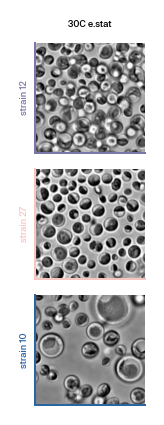

In [4]:
example_condition = "e_stat_30"
_ = cvpp.plot_strain_cell_grid(
    zroots, strains=EXAMPLE_IMAGE_STRAINS,
    experiment_indices=[EXP_CONDITIONS.index(example_condition)],
    condition_labels=[COND_TITLE[example_condition]],
    channel="BF", fov=EXAMPLE_IMAGE_FOV, n_cells=1, crop=EXAMPLE_IMAGE_CROP,
    save=True, figtitle=f"example_cells_{example_condition}_strains_{'_'.join(map(str, EXAMPLE_IMAGE_STRAINS))}",
)

### Heatmap of normalized features for all strains
Strain means over all nine FoVs, z-scored per feature across strains; strains ordered by hierarchical clustering (average linkage, Euclidean).

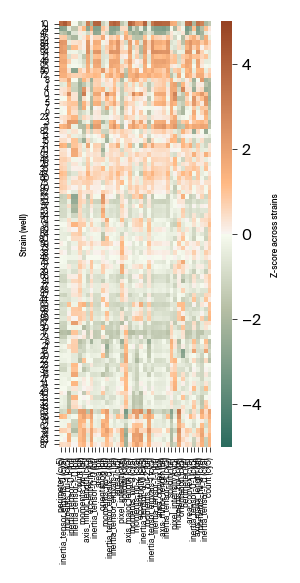

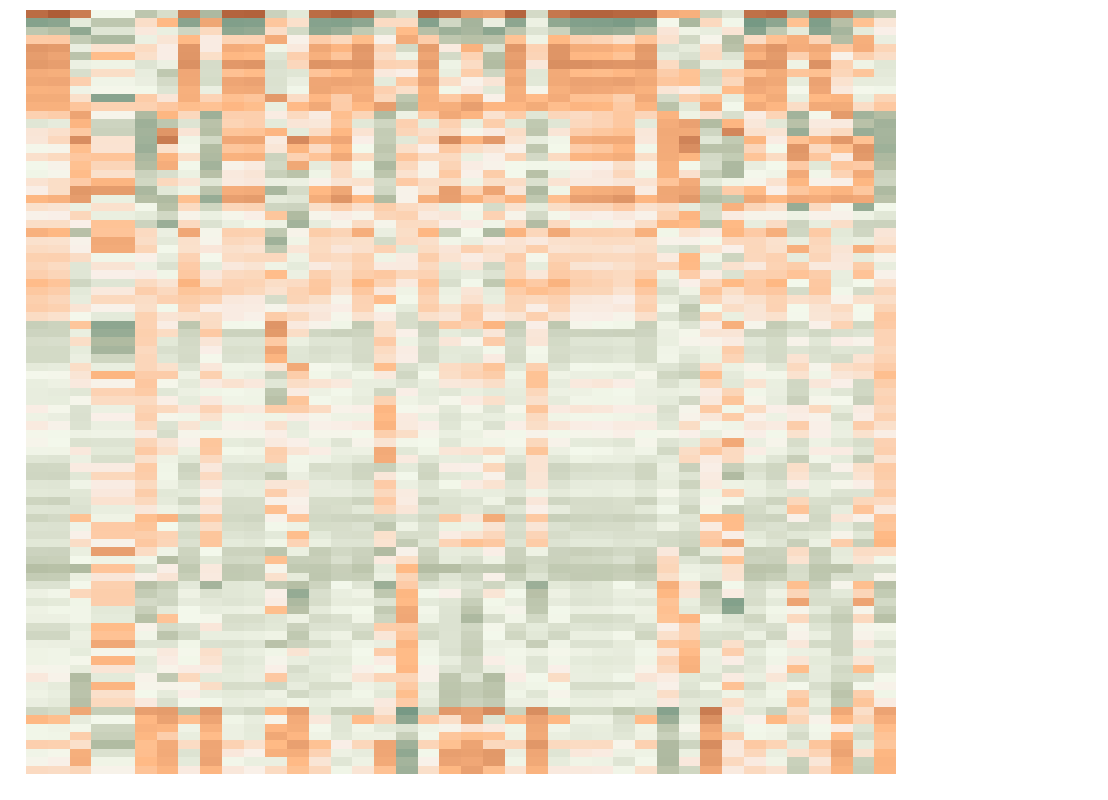

In [30]:
heatmap_condition = f"{HEATMAP_GROWTH_STAGE}_{HEATMAP_TEMPERATURE}"
fig, ax, strain_heatmap_df, strain_pfig = cvpp.plot_all_strain_feature_heatmap(
    training_data=training_data_finite,
    training_feature_labels=training_feature_labels,
    temperature=HEATMAP_TEMPERATURE,
    growth_stage=HEATMAP_GROWTH_STAGE,
    fovs=list(range(N_FOVS)),
    n_wells=N_WELLS,
    n_fovs=N_FOVS,
    dead_ids=dead_ids,
    exclude_features=EXCLUDE_FEATURES,
    normalize="zscore",
    sort_features=True,
    cluster_strains=True,
    orientation="horizontal",
    figsize=(4, 8),
    font_size=8,
    show_title=False,
    cbar_shrink=1,
    cbar_aspect=40,
    vmin=-HEATMAP_VLIM,
    vmax=HEATMAP_VLIM,
    save=True,
    figtitle=f"all_strain_feature_heatmap_{heatmap_condition}_average_of_all_fovs",
    backend="both",
    hover_fields=["strain", "feature", "value"],
    plotly_show_xticklabels=False,
    plotly_show_yticklabels=False,
    plotly_layout={"xaxis_title_text": "", "yaxis_title_text": ""},
    plotly_cbar=False,
)

### Mutants are more phenotypically diverse than wild-type isolates

Wild-type isolates (one plate, early stationary, 22 °C) are compared with the mutants at 22 °C in early and late stationary phase.

1. Dead wells are recomputed across these three plates.
2. Within-plate row/column position effects are removed (iterative median polish) before strain means are taken.
3. **Between-plate batch correction.** The WT plate was imaged on a different day, so plate and genotype are confounded. We assume the median mutant well carries no effective mutation and subtract the per-feature offset `median(mutant plate) − median(WT plate)` from every mutant well.
4. Every strain is z-scored against the WT strain distribution. Its Euclidean distance from the origin is its distance from the WT centroid.

  mut_e22: mean |batch offset| = 2.4710  (max = 50.3936)
  mut_l22: mean |batch offset| = 2.8187  (max = 57.6268)


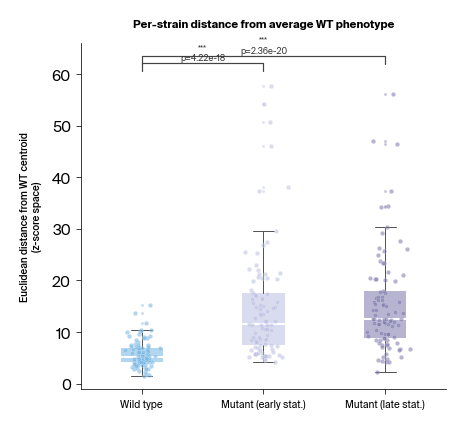

,comparison,U,p,n_wt,n_mut
0,mut_e22 vs wt_e22,1140.0,4.215778e-18,93,93
1,mut_l22 vs wt_e22,930.0,2.356253e-20,93,93


,label,n_strains,mean_dist,median_dist,std_dist,frac_gt2x_wt_median
condition,,,,,,
wt_e22,Wild type,93,5.770,5.162,2.519,0.054
mut_e22,Mutant (early stat.),93,14.780,11.566,10.740,0.602
mut_l22,Mutant (late stat.),93,15.286,12.528,9.742,0.667


In [6]:
WT_CONDS = ["mut_e22", "mut_l22", "wt_e22"]
WT_GROUP_LABELS = {"mut_e22": "Mutant (early stat.)", "mut_l22": "Mutant (late stat.)", "wt_e22": "Wild type"}
WT_GROUP_COLORS = {"mut_e22": apc.wish, "mut_l22": apc.aster, "wt_e22": apc.vital}

wt_store = cvpp.ExperimentStore(zarr_path(WT_EXPERIMENT_ID), jsonl_path(WT_EXPERIMENT_ID))
wt_zroots = [zroots[EXP_CONDITIONS.index("e_stat_22")], zroots[EXP_CONDITIONS.index("l_stat_22")], wt_store]

wt_cache = CACHE_PATH.replace(".npz", "_wt.npz")
if USE_CACHE and os.path.exists(wt_cache):
    c = np.load(wt_cache)
    wt_matrix, dead_wells_wt = c["wt"], [int(w) for w in c["dead_wells"]]
else:
    # dead wells across the two mutant plates + the WT plate
    dead_wells_wt, _ = cvpp.compute_dead_wells_and_ids(
        zroots=wt_zroots, experiments_to_check=[0, 1, 2], n_fovs=N_FOVS, n_wells=N_WELLS,
        cell_count_cutoff=CELL_COUNT_CUTOFF, channels=CHANNELS,
    )
    wt_td, wt_labels, _ = cvpp.build_training_data(
        [wt_store], exp_conditions=["wt_e22"], experiments_to_compare=[0],
        n_fovs_2_analyze=N_FOVS, n_wells=N_WELLS, include_channels=CHANNELS,
        exclude_features=EXCLUDE_FEATURES, include_pixel_intensity=True, pixel_intensity_channels=CHANNELS,
    )
    assert wt_labels == training_feature_labels
    wt_matrix = wt_td["wt_e22"]
    np.savez_compressed(wt_cache, wt=wt_matrix, dead_wells=np.array(dead_wells_wt, dtype=int))

# same preprocessing as the main matrices (mutant matrices are identical to §1's e_stat_22 / l_stat_22)
wt_td_proc, _, _ = cvpp.signed_log_transform_hu_features(
    {"wt_e22": cvpp.make_condition_matrix_finite(wt_matrix)}, training_feature_labels,
    log_base="log10", eps=HU_LOG_EPS, in_place=False,
)
wt_comparison_data = {"mut_e22": training_data_finite["e_stat_22"],
                      "mut_l22": training_data_finite["l_stat_22"],
                      "wt_e22": wt_td_proc["wt_e22"]}

# within-plate position correction, then per-strain means
wt_pos_corrected, position_effects = cvpp.correct_plate_position_effects(
    wt_comparison_data, n_wells=N_WELLS, n_rows=PLATE_ROWS, n_cols=PLATE_COLS,
    dead_wells=dead_wells_wt, n_fovs=N_FOVS, n_iter=10,
)
strain_means, strain_well_ids = {}, {}
for cond in WT_CONDS:
    strain_means[cond], strain_well_ids[cond] = cvpp.get_strain_means(
        wt_pos_corrected, condition=cond, n_wells=N_WELLS, n_fovs=N_FOVS, dead_wells=dead_wells_wt)

# between-plate batch correction, z-score vs WT, distance from WT centroid
strain_means_bc, batch_offsets = cvpp.batch_correct_to_wt(strain_means, wt_key="wt_e22",
                                                         mutant_keys=("mut_e22", "mut_l22"))
z_scores_vs_wt, wt_distances, mu_wt, sigma_wt = cvpp.compute_wt_zscores_and_distances(strain_means_bc)

fig, ax, wt_distance_tests = cvpp.plot_wt_distance(
    wt_distances, WT_GROUP_LABELS, WT_GROUP_COLORS, cond_order=("wt_e22", "mut_e22", "mut_l22"),
    random_state=RANDOM_STATE, save=True, figtitle="per_strain_wt_distance",
)
display(save_table(wt_distance_tests, "wt_distance_mann_whitney.csv", index=False))
display(save_table(cvpp.summarize_wt_distances(wt_distances, WT_GROUP_LABELS), "wt_distance_summary.csv").round(3))

## 3 · Reliable features organize phenotypic variation across conditions

### A · Feature reliability (ICC)
For each feature and condition: one-way random-effects model with wells as the random factor and the nine FoVs as replicates. ICC(1,1) is the fraction of a single field's variance that is strain-level. Significance comes from permuting measurements across wells. The heatmap shows ICC averaged across conditions.

/Users/rockwell/repos/2026-chlorella-phenotyping/chlorella_phenotyping_pub/cvp_pub.py:3670: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



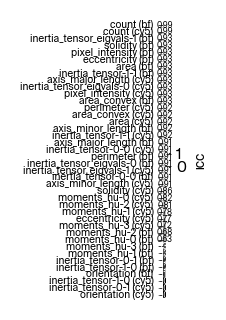

Saved heatmap values to results/feature_icc_single_column_gray_values.csv


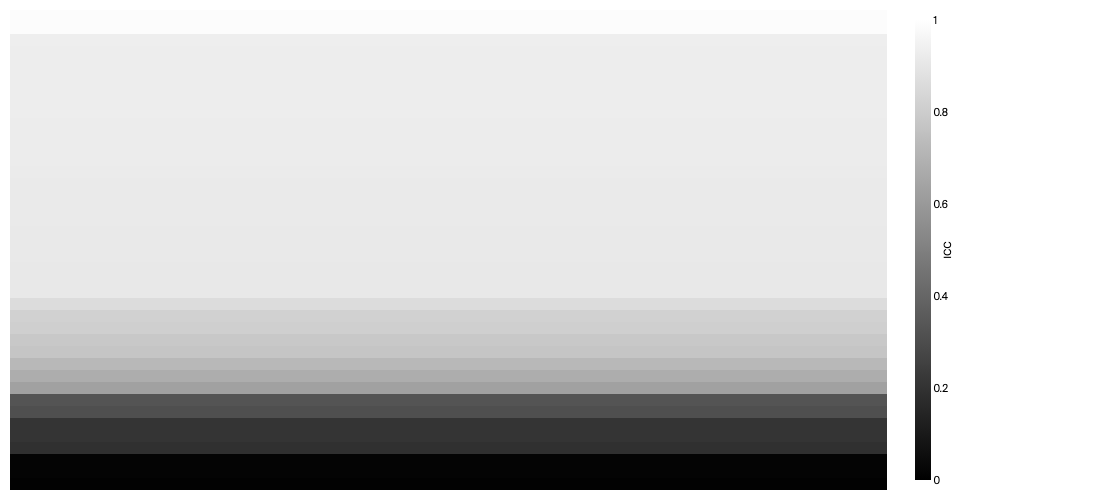

32 features with mean ICC >= 0.5


,count (bf),count (cy5),inertia_tensor_eigvals-1 (bf),solidity (bf),pixel_intensity (bf),eccentricity (bf),area (bf),inertia_tensor-1-1 (bf),axis_major_length (cy5),inertia_tensor_eigvals-0 (cy5),...,moments_hu-2 (bf),moments_hu-0 (bf),moments_hu-3 (bf),moments_hu-1 (bf),inertia_tensor-0-1 (bf),inertia_tensor-1-0 (bf),orientation (bf),inertia_tensor-0-1 (cy5),inertia_tensor-1-0 (cy5),orientation (cy5)
mean_icc,0.99,0.99,0.93,0.93,0.93,0.93,0.93,0.93,0.93,0.93,...,0.68,0.63,0.33,0.31,0.21,0.21,0.19,0.01,0.01,0.01


In [43]:
from importlib import reload
reload(cvpp)

icc_results = cvpp.compute_feature_icc(
    training_data=training_data_finite,
    training_feature_labels=training_feature_labels,
    condition_order=EXP_CONDITIONS,
    n_wells=N_WELLS,
    n_fovs=N_FOVS,
    dead_ids=dead_ids,
    n_permutations=ICC_N_PERMUTATIONS,
    n_split_half_repeats=ICC_SPLIT_HALF_REPEATS,
    icc_threshold=0.8,
)
save_table(icc_results["table"], "icc_results.csv", index=False)

fig, ax, icc_df, icc_pfig = cvpp.plot_feature_icc_heatmap(
    icc_results,
    metric="icc_single",
    cbar=True,
    save_cbar_separately=True,   
    cbar_label="ICC",
    column="mean",
    sort_features=True,
    exclude_features=[],
    figsize=(.05, 5),
    cmap="gray",
    vmin=0,
    vmax=1,
    icc_threshold=0,
    save=True,
    figtitle="feature_icc_single_column_gray",
    backend="both",
    plotly_width=80,
    plotly_show_yticklabels=False,
    hover_fields=["feature", "value"],
    plotly_annot=False,
)

# mean ICC per feature (used for the reliable-feature set and quoted in the text)
mean_icc = pd.Series(np.nanmean(icc_results["icc_single"], axis=1), index=training_feature_labels, name="mean_icc")
reliable = np.where(mean_icc.values >= ICC_RELIABLE_THRESHOLD)[0]
print(f"{len(reliable)} features with mean ICC >= {ICC_RELIABLE_THRESHOLD}")
save_table(mean_icc.sort_values(ascending=False).to_frame(), "mean_icc_per_feature.csv").round(2).T

### B–E · t-SNE of z-scored features
One point per field of view, all strains and conditions (perplexity 50, random state 28). Colored by condition and by area, Hu moment 0, and orientation (bright-field).

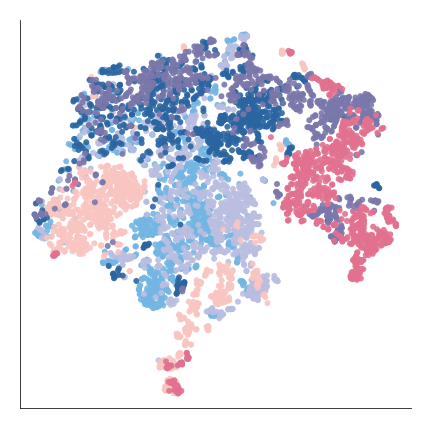

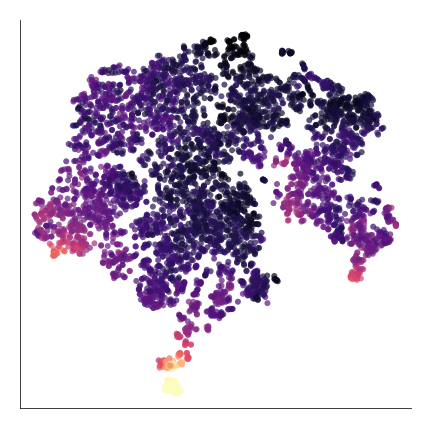

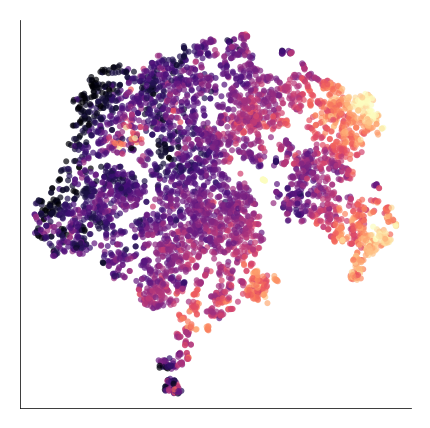

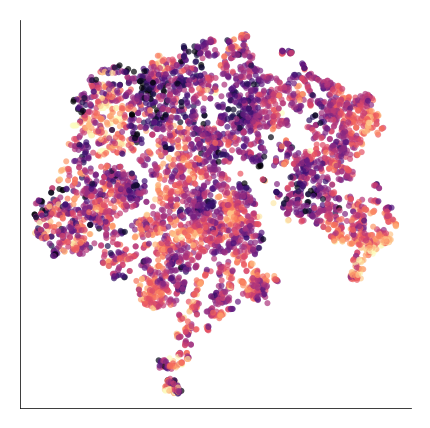

In [8]:
tsne_z = cvpp.tsne_standardized(all_dat, perplexity=TSNE_PERPLEXITY, random_state=TSNE_RANDOM_STATE)

cvpp.plot_tsne(
    input_dat=all_dat, exp_embedding=tsne_z, exp_colors=CONDITION_COLORS,
    n_fovs=N_FOVS, dead_well_ids=dead_ids,
    figtitle="tsne_colored_by_experimental_condition_zscored", hide_in_cell=False,
)

color_features = training_feature_labels if TSNE_COLOR_FEATURES == "all" else TSNE_COLOR_FEATURES
for feat in color_features:
    cvpp.plot_tsne(
        input_dat=all_dat, exp_embedding=tsne_z, exp_colors=CONDITION_COLORS,
        n_fovs=N_FOVS, dead_well_ids=dead_ids,
        figtitle=f"tsne_colored_by_{cvpp.safe_feature_name(feat)}_zscored",
        tsne_alpha=.9, feat_2_color_by=training_feature_labels.index(feat),
        feat_cmap="magma", feat_alpha=.7, hide_in_cell=False,
    )

## 4 · The environment observably modulates phenotypes

### A · Example cells across temperatures (early stationary)
One bright-field and one Cy5 grid. The pub panel is a merge of the two channels, done at layout time.

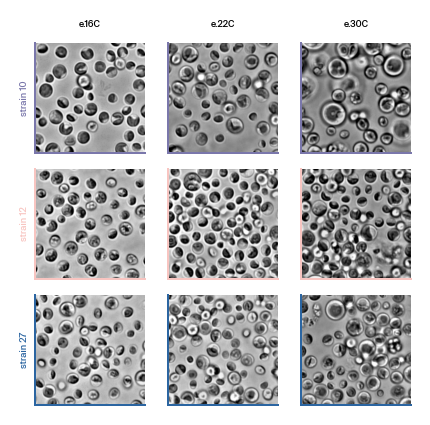

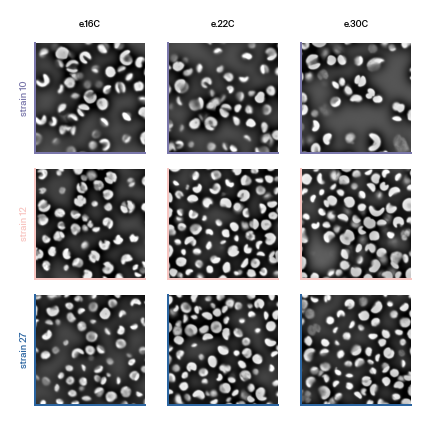

In [9]:
for channel in CHANNELS:
    _ = cvpp.plot_strain_cell_grid(
        zroots, strains=TRAJ_STRAINS,
        experiment_indices=[EXP_CONDITIONS.index(c) for c in TRAJ_CONDITIONS],
        condition_labels=TRAJ_CONDITION_LABELS, channel=channel, fov=EXAMPLE_IMAGE_FOV,
        n_cells=1, crop=EXAMPLE_IMAGE_CROP, save=True,
        figtitle=f"trajectory_example_cells_{channel.lower()}_strains_{'_'.join(map(str, TRAJ_STRAINS))}",
    )

### B · Strain trajectories across temperatures
PCA on strain means of the reliable features (mean ICC ≥ `ICC_RELIABLE_THRESHOLD`), each feature z-scored with one mean and SD pooled across `TRAJ_PCA_CONDITIONS`. The first plot highlights the example strains; the second shows every strain.

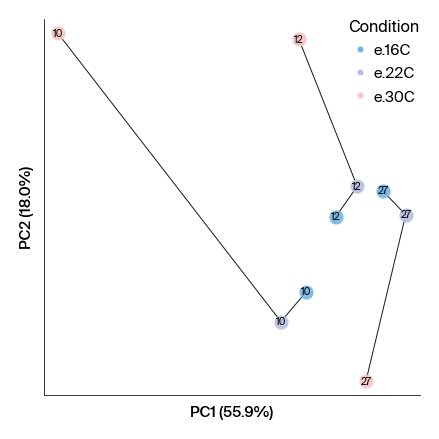

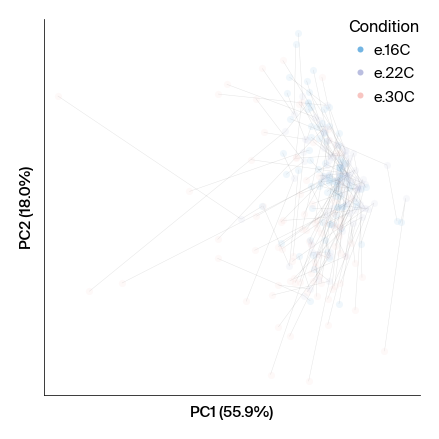

In [10]:
training_data_reliable = {c: training_data_finite[c][:, reliable] for c in EXP_CONDITIONS}
traj_colors = [COND_COLOR[c] for c in TRAJ_CONDITIONS]

_ = cvpp.plot_strain_pca_trajectories_standardized(
    training_data=training_data_reliable,
    exp_conditions=TRAJ_CONDITIONS,
    pca_conditions=TRAJ_PCA_CONDITIONS,
    strains_to_plot=TRAJ_STRAINS,
    n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
    line_width=1, point_size=200,
    condition_labels=TRAJ_CONDITION_LABELS, condition_colors=traj_colors,
    fit_pca_on="all_strains", show_variance_explained=True, show_title=False,
    figsize=(6, 6), save=True,
    figtitle=f"strain_{'_'.join(map(str, TRAJ_STRAINS))}_pca_trajectories_icc{ICC_RELIABLE_THRESHOLD}_zscored",
)

_ = cvpp.plot_strain_pca_trajectories_standardized(
    training_data=training_data_reliable,
    exp_conditions=TRAJ_CONDITIONS,
    pca_conditions=TRAJ_PCA_CONDITIONS,
    strains_to_plot=live_strains,
    n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
    point_size=50, alpha=.1, line_width=.5, annotate_points=False,
    condition_labels=TRAJ_CONDITION_LABELS, condition_colors=traj_colors,
    fit_pca_on="all_strains", show_variance_explained=True, show_title=False,
    figsize=(6, 6), save=True,
    figtitle=f"all_strains_pca_trajectories_icc{ICC_RELIABLE_THRESHOLD}_zscored",
)

## 5 · Phenotypes are predictable in held-out environments

Each condition is held out in turn and predicted from the other five with ridge regression (`RIDGE_ALPHA`, features standardized within each training fold). Cross-validation folds are grouped by well (`N_CV_SPLITS`), so no field of a held-out strain is used in training. Dead wells are dropped.

### Schematic

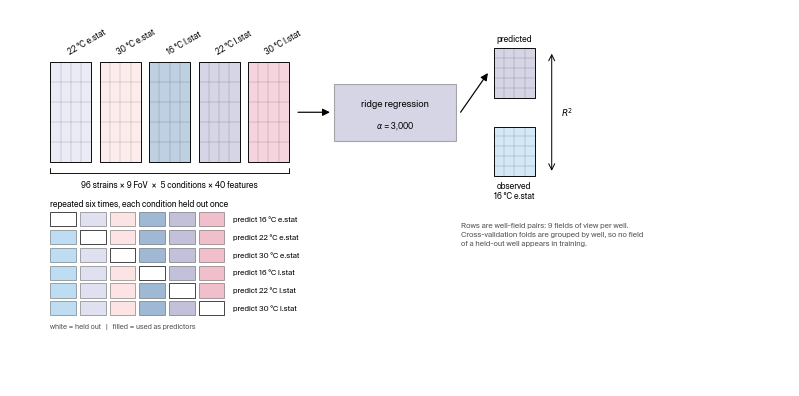

In [11]:
fig, ax = cvpp.plot_model_schematic(
    condition_labels=[t.replace("C ", " °C ") for t in CONDITION_TITLES],
    condition_colors=CONDITION_COLORS,
    held_out_index=0,
    n_rows_label=f"{N_WELLS} strains × {N_FOVS} FoV",
    n_features=len(training_feature_labels),
    ridge_alpha=RIDGE_ALPHA,
    save=True,
    figtitle="model_schematic",
)

### A · Ridge regression vs. recalibrated strain-mean baseline
The baseline takes each strain's mean across the five training conditions and maps it onto the held-out condition with a per-feature linear fit estimated on the training strains (strain identity plus each condition's shift and scale, but no way for strains with the same average to respond differently). R² is averaged across features.

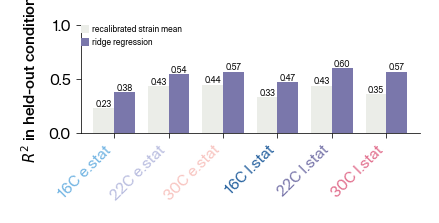

model,ridge,strain_mean_recal,gap
condition,,,
e_stat_16,0.375,0.225,0.150
e_stat_22,0.545,0.433,0.112
e_stat_30,0.567,0.444,0.123
l_stat_16,0.468,0.330,0.138
l_stat_22,0.599,0.434,0.165
l_stat_30,0.567,0.353,0.213
mean,0.520,0.370,0.150


In [58]:
well_groups = cvpp.well_groups(N_WELLS, N_FOVS)
keep_rows = np.setdiff1d(np.arange(N_WELLS * N_FOVS), np.asarray(dead_ids, dtype=int))
live_input = {c: training_data_finite[c][keep_rows] for c in EXP_CONDITIONS}

recal_results = cvpp.compare_models_condition_holdout_cv_recalibrated(
    live_input,
    exp_conditions=EXP_CONDITIONS,
    ridge_alpha=RIDGE_ALPHA,
    n_splits=N_CV_SPLITS,
    groups=well_groups[keep_rows],
)

fig, ax, r2_df = cvpp.plot_ridge_vs_recalibrated_r2(
    recal_results, col_titles=CONDITION_TITLES, xtick_colors=CONDITION_COLORS, save=True,
)

r2_table = (r2_df.pivot(index="condition", columns="model", values="value")
            .reindex(EXP_CONDITIONS)
            .assign(gap=lambda d: d["ridge"] - d["strain_mean_recal"]))
r2_table.loc["mean"] = r2_table.mean()
save_table(r2_table, "model_r2_ridge_vs_baseline.csv").round(3)

### A2 · Separating feature pooling from strain × environment interaction
Ridge sees every feature in each training condition, so its gain over the recalibrated strain mean could come from two sources: pooling features (a less noisy estimate of each strain) or condition-resolved information (how a strain changed between conditions). The condition-averaged ridge control pools every feature but sees only each strain's average across the training conditions. Its gain over the strain mean is the pooling effect, and the full model's gain over it is the condition-resolved (interaction) effect. Its penalty is `RIDGE_ALPHA / 5` so shrinkage per predictor matches the full model.

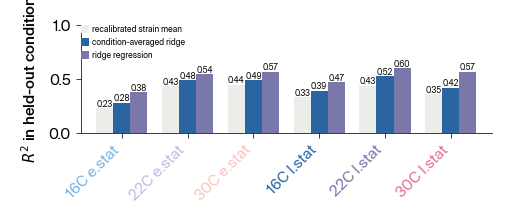

37 of 40 features gain from condition-resolved information


model,strain_mean_recal,ridge_strain_profile,ridge,pooling_gain,interaction_gain
condition,,,,,
e_stat_16,0.225,0.277,0.375,0.052,0.098
e_stat_22,0.433,0.484,0.545,0.051,0.061
e_stat_30,0.444,0.486,0.567,0.042,0.081
l_stat_16,0.330,0.390,0.468,0.060,0.077
l_stat_22,0.434,0.524,0.599,0.090,0.075
l_stat_30,0.353,0.418,0.567,0.065,0.149
mean,0.370,0.430,0.520,0.060,0.090


In [59]:
# recal_results (cell above) already contains a third model, ridge_strain_profile:
# ridge on each strain's CONDITION-AVERAGED profile of all features. Like the full model it
# pools every feature, but it can't see how a strain changed between training conditions.
#   ridge_strain_profile - strain_mean_recal : gain from pooling features (denoising)
#   ridge - ridge_strain_profile             : gain from condition-resolved (strain x environment) information
BASELINE_MODELS = ("strain_mean_recal", "ridge_strain_profile", "ridge")

fig, ax, r2_3_df = cvpp.plot_ridge_vs_recalibrated_r2(
    recal_results, models=BASELINE_MODELS,
    col_titles=CONDITION_TITLES, xtick_colors=CONDITION_COLORS,
    bar_width=0.26, figsize=(7, 3),
    save=True, figtitle="ridge_vs_strain_mean_and_profile_baselines_r2",
)

gain_table = (r2_3_df.pivot(index="condition", columns="model", values="value")
              .reindex(EXP_CONDITIONS)[list(BASELINE_MODELS)]
              .assign(pooling_gain=lambda d: d["ridge_strain_profile"] - d["strain_mean_recal"],
                      interaction_gain=lambda d: d["ridge"] - d["ridge_strain_profile"]))
gain_table.loc["mean"] = gain_table.mean()

# same split per feature (R² averaged across held-out conditions)
per_feature_gain = pd.DataFrame(
    {m: np.nanmean(recal_results[m]["r2_per_feature"], axis=0) for m in BASELINE_MODELS},
    index=training_feature_labels,
).assign(interaction_gain=lambda d: d["ridge"] - d["ridge_strain_profile"]).sort_values(
    "interaction_gain", ascending=False)
save_table(per_feature_gain, "model_r2_per_feature_ridge_vs_profile_baseline.csv")
print(f"{(per_feature_gain.interaction_gain > 0).sum()} of {len(per_feature_gain)} features gain "
      "from condition-resolved information")

save_table(gain_table, "model_r2_ridge_vs_profile_baseline.csv").round(3)


### B · Distance between predicted and observed phenotypes
Out-of-fold predictions and observations are z-scored per feature within condition (observed mean and SD). Each field's distance between predicted and observed is divided by the error of predicting the population mean. One point per field of view.

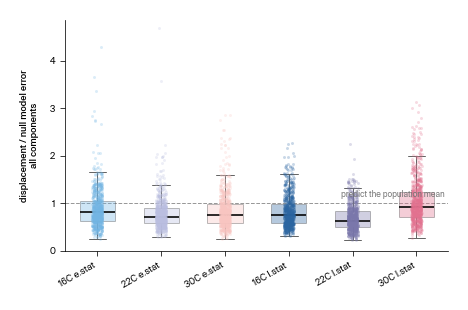

,median_normalized_distance
condition,
e_stat_16,0.811
e_stat_22,0.709
e_stat_30,0.758
l_stat_16,0.748
l_stat_22,0.630
l_stat_30,0.916


In [13]:
disp_input = cvpp.zscored_oof_predictions(
    training_data_finite, EXP_CONDITIONS, ridge_alpha=RIDGE_ALPHA, n_splits=N_CV_SPLITS,
    groups=well_groups, n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids, random_state=RANDOM_STATE,
)
fig, ax, disp = cvpp.plot_prediction_displacements(
    disp_input, EXP_CONDITIONS, col_titles=CONDITION_TITLES, condition_colors=CONDITION_COLORS,
    n_components=None,      # None = all features (full distance)
    normalize=True,         # divide by the "predict the population mean" error
    save=True, figtitle="prediction_displacement_distributions_oof_zscored",
)
disp_median = disp.groupby("condition").displacement.median().reindex(EXP_CONDITIONS)
save_table(disp_median.to_frame("median_normalized_distance"), "prediction_displacement_medians.csv").round(3)

### C · Calibration slopes
Observed strain means regressed on out-of-fold predicted strain means, per feature and condition. A slope of 1 means the predictions span the right range.

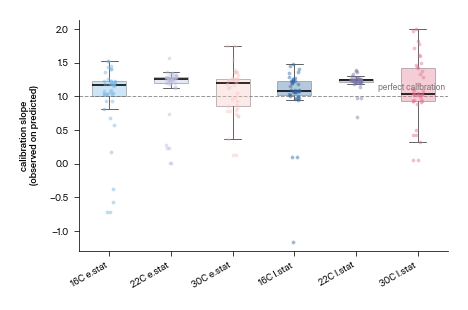

,median_slope
condition,
e_stat_16,1.17
e_stat_22,1.26
e_stat_30,1.20
l_stat_16,1.09
l_stat_22,1.25
l_stat_30,1.04


In [29]:
calib = cvpp.compute_prediction_calibration(
    training_data_finite, EXP_CONDITIONS, training_feature_labels,
    ridge_alpha=RIDGE_ALPHA, n_splits=N_CV_SPLITS, groups=well_groups,
    n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids, random_state=RANDOM_STATE,
)
cvpp.plot_prediction_calibration(calib, EXP_CONDITIONS, CONDITION_TITLES, CONDITION_COLORS,
                                 save=True, figtitle="prediction_calibration_slopes")
save_table(calib, "prediction_calibration.csv", index=False)
calib.groupby("condition").slope.median().reindex(EXP_CONDITIONS).to_frame("median_slope").round(2)

### D · Ridge R² for each feature in each held-out condition

/Users/rockwell/repos/2026-chlorella-phenotyping/chlorella_phenotyping_pub/cvp_pub.py:1106: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



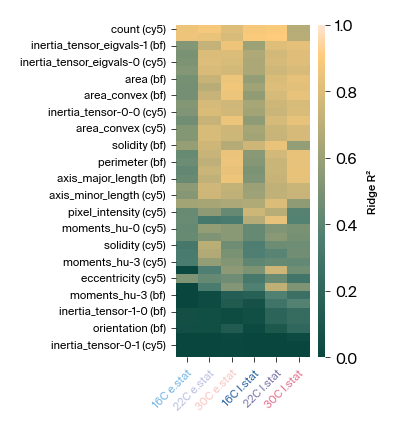

Saved heatmap values to results/sorted_r2_per_feature_values.csv


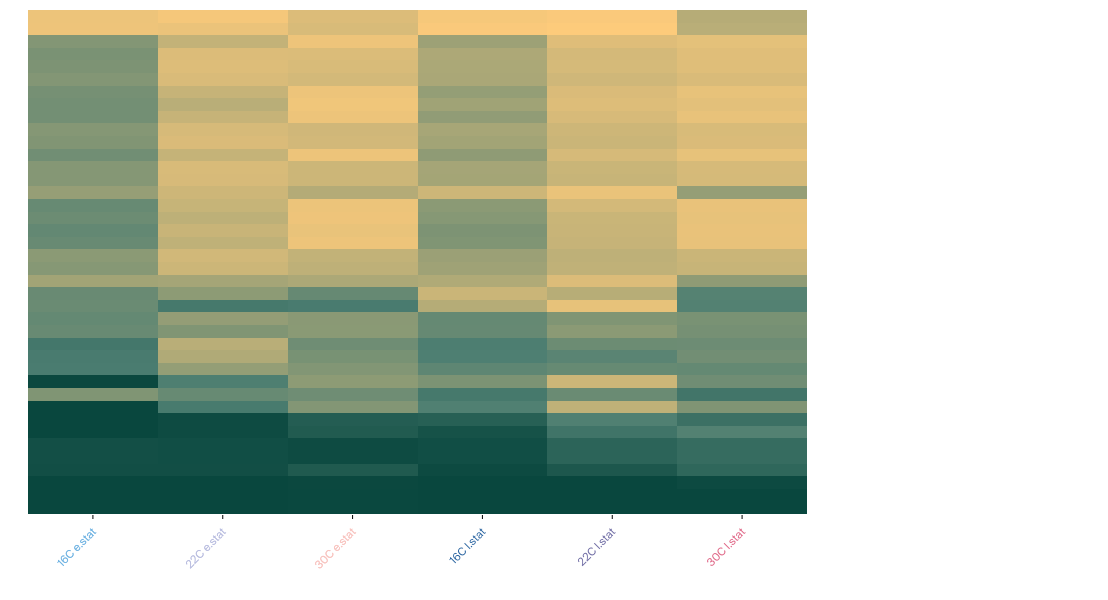

,e_stat_16,e_stat_22,e_stat_30,l_stat_16,l_stat_22,l_stat_30
count (bf),0.85,0.84,0.78,0.89,0.90,0.69
area (bf),0.48,0.73,0.85,0.58,0.79,0.83
area_convex (bf),0.47,0.73,0.85,0.56,0.78,0.83
perimeter (bf),0.45,0.71,0.85,0.53,0.74,0.83
eccentricity (bf),0.62,0.63,0.65,0.66,0.80,0.56
solidity (bf),0.58,0.75,0.67,0.75,0.84,0.58
axis_major_length (bf),0.44,0.71,0.85,0.51,0.73,0.84
axis_minor_length (bf),0.47,0.69,0.86,0.61,0.80,0.82
orientation (bf),0.05,0.05,0.12,0.02,0.11,0.20
moments_hu-0 (bf),-0.00,0.33,0.52,0.36,0.71,0.51


In [44]:
fig, ax, sorted_r2_df, r2_pfig = cvpp.plot_sorted_r2_per_feature(
    ridge_model_residulals={"real": {"r2_per_feature": recal_results["ridge"]["r2_per_feature"],
                                     "r2_overall": recal_results["ridge"]["overall_r2"]},
                            "conditions": EXP_CONDITIONS},
    training_feature_labels=training_feature_labels,
    xtick_colors=CONDITION_COLORS,
    x_tick_rotation=45,
    col_titles=CONDITION_TITLES,
    figsize=(3, 6),
    font_size=11,
    annot=False,
    cbar=True,
    save_cbar_separately=True,   # new
    cbar_label="Ridge R²",
    cbar_shrink=1,
    cbar_aspect=50,
    orientation="horizontal",
    save=True,
    backend="both",
    hover_fields=["feature", "condition", "value"],
    plotly_show_xticklabels=True,
    plotly_show_yticklabels=False,
    plotly_layout={"xaxis_title_text": "", "yaxis_title_text": ""},
    plotly_cbar=False,
)
r2_per_feature = pd.DataFrame(recal_results["ridge"]["r2_per_feature"].T,
                              index=training_feature_labels, columns=EXP_CONDITIONS)
save_table(r2_per_feature, "ridge_r2_per_feature.csv").round(2)

## 6 · Predictability arises from structured variance

### A · Variance partitioning
Two-way ANOVA per feature on field-level values (Type II sums of squares; feature ~ strain + environment + strain × environment). The residual is field-to-field variation. Fractions are η².

/Users/rockwell/repos/2026-chlorella-phenotyping/chlorella_phenotyping_pub/cvp_pub.py:1404: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



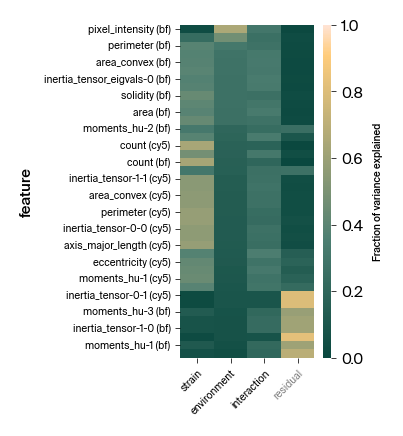

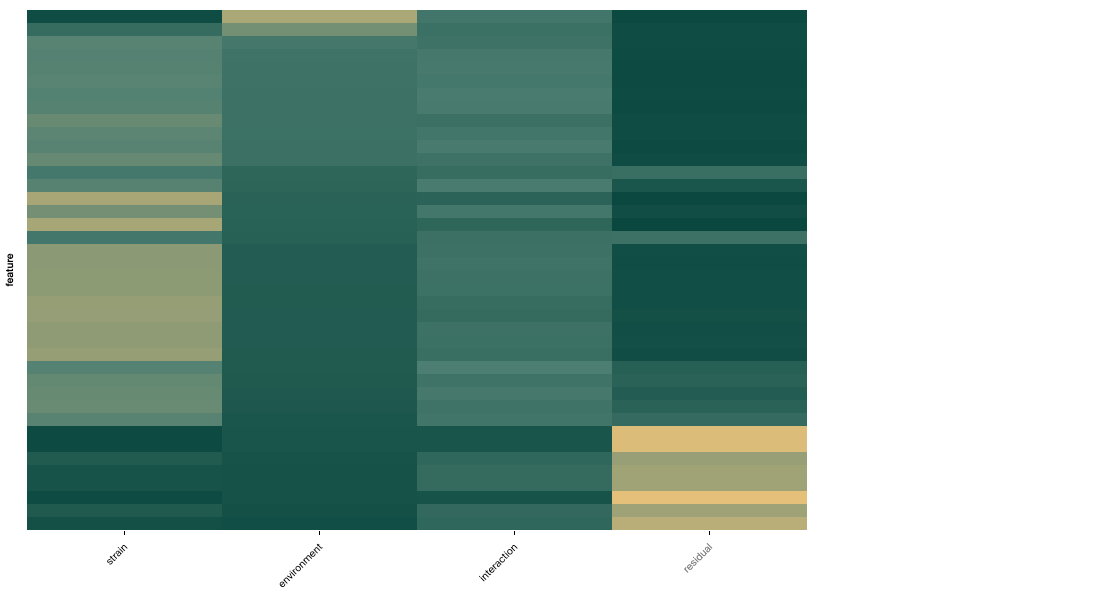

,feature,ss_strain,ss_environment,ss_interaction,ss_residual,frac_strain,frac_environment,frac_interaction,frac_residual,mean_ridge_r2
0,count (bf),6.434780e+07,1.670088e+07,2.015673e+07,7.530047e+05,0.631118,0.163801,0.197696,0.007385,0.827390
1,area (bf),3.094176e+07,2.116234e+07,2.600930e+07,1.697016e+06,0.387691,0.265158,0.325889,0.021263,0.710341
2,area_convex (bf),3.203758e+07,2.322785e+07,2.702979e+07,1.823140e+06,0.380863,0.276133,0.321330,0.021674,0.705729
3,perimeter (bf),1.053413e+05,8.482368e+04,7.472731e+04,8.047914e+03,0.385950,0.310778,0.273786,0.029486,0.685511
4,eccentricity (bf),3.086390e+00,1.114866e+00,2.008672e+00,2.807023e-01,0.475515,0.171765,0.309473,0.043247,0.652497
5,solidity (bf),7.690253e-02,4.737730e-02,4.611414e-02,5.542826e-03,0.437103,0.269286,0.262106,0.031505,0.696406
6,axis_major_length (bf),9.586213e+03,6.299900e+03,7.099500e+03,7.065428e+02,0.404615,0.265907,0.299656,0.029822,0.680104
7,axis_minor_length (bf),1.005592e+04,6.170020e+03,6.447683e+03,7.120265e+02,0.430004,0.263838,0.275711,0.030447,0.709480
8,orientation (bf),5.983249e-01,4.456103e-01,2.082201e+00,7.033486e+00,0.058892,0.043861,0.204949,0.692298,0.090832
9,moments_hu-0 (bf),3.643314e-02,1.852803e-02,3.111559e-02,3.202654e-02,0.308485,0.156880,0.263461,0.271174,0.405498


In [33]:
variance_df = cvpp.compute_variance_partitioning_by_feature(
    training_data=training_data_finite,
    training_feature_labels=training_feature_labels,
    condition_order=EXP_CONDITIONS,
    n_wells=N_WELLS,
    n_fovs=N_FOVS,
    dead_ids=dead_ids,
)
variance_df["mean_ridge_r2"] = variance_df["feature"].map(
    dict(zip(training_feature_labels, np.nanmean(recal_results["ridge"]["r2_per_feature"], axis=0))))

fig, ax, vp_plot_df, var_pfig = cvpp.plot_variance_partitioning_heatmap(
    variance_df,
    orientation="horizontal",
    sort_features=True,
    sort_by="environment",
    show_title=False,
    figsize=(3, 6),
    xtick_colors=["black", "black", "black", "grey"],
    cbar_shrink=1,
    cbar_aspect=40,
    save=True,
    cmap="apc:verde",
    backend="both",
    hover_fields=["feature", "component", "value"],
    plotly_show_xticklabels=True,
    plotly_show_yticklabels=False,
    plotly_cbar=False,
)
save_table(variance_df, "variance_partitioning.csv", index=False)

### B · Correlation between mean ridge R² and each variance fraction

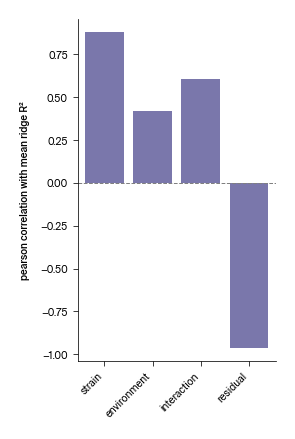

,component,correlation
0,strain,0.878886
1,environment,0.416348
2,interaction,0.605650
3,residual,-0.962414


In [17]:
merged_df = cvpp.merge_variance_and_ridge_results(
    variance_df=variance_df,
    comparison_results=recal_results,
    training_feature_labels=training_feature_labels,
    model_name="ridge",
)
fig, ax, corr_df = cvpp.plot_ridge_variance_component_correlations(
    merged_df, method="pearson", figsize=(4, 6), save=True, show_title=False,
    figtitle="ridge_vs_variance_component_correlations_long",
)
save_table(corr_df, "ridge_vs_variance_component_correlations.csv")

### C · Mean ridge R² vs. residual fraction

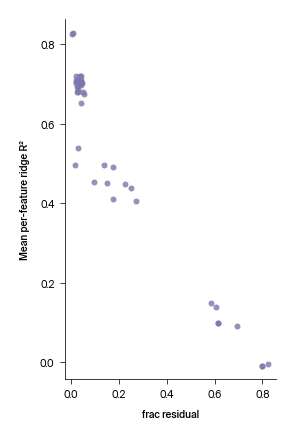

In [18]:
fig, ax = cvpp.plot_ridge_vs_variance_component(
    merged_df, component="frac_residual", figsize=(4, 6), save=True, show_title=False,
    figtitle="ridge_vs_residual_fraction_long",
)

## 7 · Phenotypic interaction structure beyond strain identity

### A · Strains 37 and 94 across temperatures (late stationary)

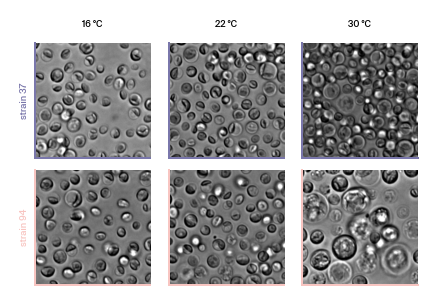

In [57]:
_ = cvpp.plot_strain_pair_cell_grid(
    zroots, strain_a=DEPARTURE_STRAINS[0], strain_b=DEPARTURE_STRAINS[1],
    experiment_indices=[EXP_CONDITIONS.index(c) for c in DEPARTURE_CONDITIONS],
    condition_labels=DEPARTURE_CONDITION_LABELS, channel="BF", fov=EXAMPLE_IMAGE_FOV,
    n_cells=1, crop=EXAMPLE_IMAGE_CROP, save=True,
    figtitle=f"departure_example_cells_{DEPARTURE_STRAINS[0]}_{DEPARTURE_STRAINS[1]}",
)

### B · Observed vs. expected reaction norms
For each feature: out-of-fold ridge predictions (all six conditions, grouped by well) are rescaled with the calibration fit. Each strain's mean residual in a condition is compared with the residuals of all other strains in that condition (robust z from median and MAD). Benjamini–Hochberg correction is applied across all strains and conditions. Values are z-scored across strains within each condition; error bars are ±1 SEM across FoVs; an asterisk marks q < `FDR_Q`.

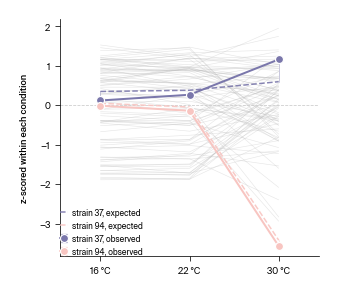

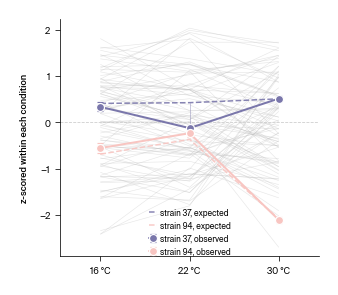

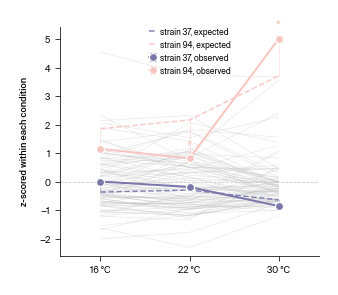

,feature,strain,condition,obs_z,pred_z,resid_z,q
307,count (bf),37,l_stat_16,0.125,0.353,-0.228,0.978
362,count (bf),94,l_stat_16,-0.010,0.052,-0.062,0.988
398,count (bf),37,l_stat_22,0.270,0.383,-0.114,0.978
453,count (bf),94,l_stat_22,-0.136,-0.041,-0.095,0.978
489,count (bf),37,l_stat_30,1.164,0.601,0.564,0.978
544,count (bf),94,l_stat_30,-3.566,-3.417,-0.149,0.980
307,eccentricity (bf),37,l_stat_16,0.337,0.412,-0.076,0.990
362,eccentricity (bf),94,l_stat_16,-0.554,-0.687,0.133,0.984
398,eccentricity (bf),37,l_stat_22,-0.123,0.428,-0.551,0.664
453,eccentricity (bf),94,l_stat_22,-0.233,-0.367,0.134,0.984


significant (q < 0.05):


,feature,strain,condition,obs_z,pred_z,resid_z,q
453,area (bf),94,l_stat_22,0.8172,2.1663,-1.3491,0.0011
544,area (bf),94,l_stat_30,5.0126,3.7170,1.2955,0.0040


In [20]:
departure_rows = []
for feat in DEPARTURE_FEATURES:
    dep_df = cvpp.compute_strain_departures(
        training_data_finite, EXP_CONDITIONS, training_feature_labels,
        feature=feat, ridge_alpha=RIDGE_ALPHA, n_splits=N_CV_SPLITS,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids, random_state=RANDOM_STATE,
    )
    cvpp.plot_reaction_norm_vs_prediction(
        dep_df, strains=DEPARTURE_STRAINS, conditions=DEPARTURE_CONDITIONS,
        condition_labels=DEPARTURE_CONDITION_LABELS, q_threshold=FDR_Q, save=True,
        figtitle=f"reaction_norm_vs_prediction_{'_'.join(map(str, DEPARTURE_STRAINS))}_{cvpp.safe_feature_name(feat)}",
    )
    sub = dep_df[dep_df.strain.isin(DEPARTURE_STRAINS) & dep_df.condition.isin(DEPARTURE_CONDITIONS)].copy()
    sub["feature"] = feat
    departure_rows.append(sub)

departure_values = pd.concat(departure_rows)[["feature", "strain", "condition", "obs_z", "pred_z", "resid_z", "q"]]
save_table(departure_values, "strain_departures_figure_values.csv", index=False)
display(departure_values.round(3))
print(f"significant (q < {FDR_Q}):")
departure_values[departure_values.q < FDR_Q].round(4)

---
# Supplemental analyses

Each block runs only if its flag in `RUN_SUPPLEMENTAL` is `True`.

## S1 · Ridge alpha scan
Mean held-out R² for alpha = 2¹ … 2¹⁶. With `ALPHA_SCAN_GROUPED = False` this reproduces the original scan, which uses shuffled K-fold over all rows. Fields of the same well can then appear in both training and test folds. Set it to `True` to use the GroupKFold-by-well scheme of the final model.

alpha =       2  mean overall R2 = -0.070  (mean of per-condition median feature R2 = 0.193)
alpha =       4  mean overall R2 = 0.020  (mean of per-condition median feature R2 = 0.224)
alpha =       8  mean overall R2 = 0.106  (mean of per-condition median feature R2 = 0.282)
alpha =      16  mean overall R2 = 0.180  (mean of per-condition median feature R2 = 0.333)
alpha =      32  mean overall R2 = 0.242  (mean of per-condition median feature R2 = 0.367)
alpha =      64  mean overall R2 = 0.295  (mean of per-condition median feature R2 = 0.392)
alpha =     128  mean overall R2 = 0.342  (mean of per-condition median feature R2 = 0.414)
alpha =     256  mean overall R2 = 0.383  (mean of per-condition median feature R2 = 0.440)
alpha =     512  mean overall R2 = 0.416  (mean of per-condition median feature R2 = 0.479)
alpha =    1024  mean overall R2 = 0.439  (mean of per-condition median feature R2 = 0.502)
alpha =    2048  mean overall R2 = 0.449  (mean of per-condition median feature

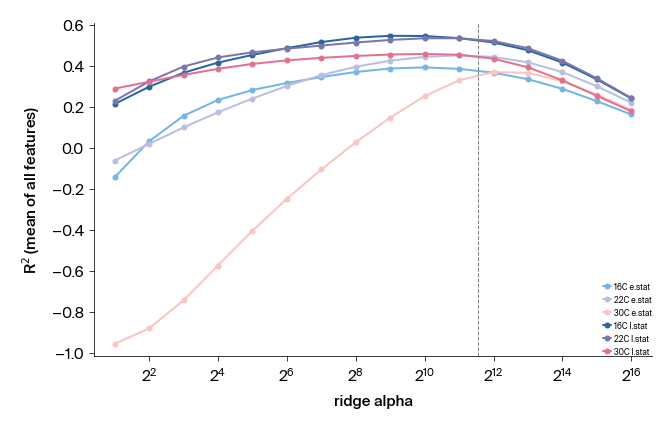

In [21]:
if RUN_SUPPLEMENTAL["alpha_scan"]:
    if ALPHA_SCAN_GROUPED:
        alpha_scan_df = cvpp.ridge_alpha_scan(live_input, EXP_CONDITIONS, ALPHA_SCAN_ALPHAS,
                                              n_splits=N_CV_SPLITS, grouped=True,
                                              groups=well_groups[keep_rows])
    else:
        alpha_scan_df = cvpp.ridge_alpha_scan(training_data_finite, EXP_CONDITIONS, ALPHA_SCAN_ALPHAS,
                                              n_splits=N_CV_SPLITS, grouped=False)
    save_table(alpha_scan_df, "ridge_alpha_scan.csv", index=False)
    cvpp.plot_alpha_scan(alpha_scan_df, EXP_CONDITIONS, CONDITION_COLORS, col_titles=CONDITION_TITLES,
                         chosen_alpha=RIDGE_ALPHA, save=True,
                         figtitle="alpha_scan_conditional_cross_validated_holdout_16split")

## S2 · Strain identity (one confusion matrix per condition)
Can a strain's out-of-fold predicted phenotype be matched back to its observed phenotype among all strains? Also shown: identifying the condition from a phenotype, and the distribution of identity probabilities.

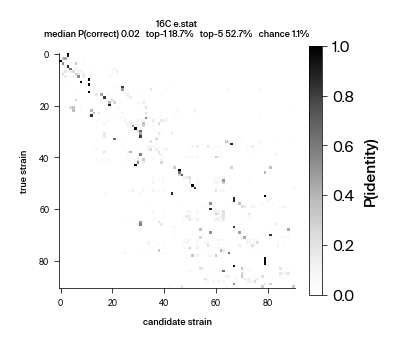

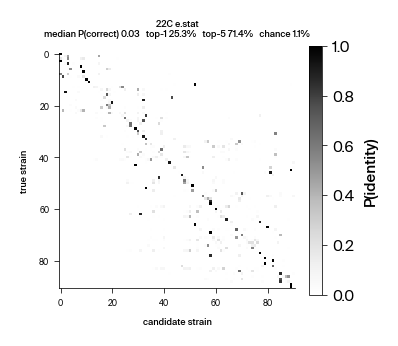

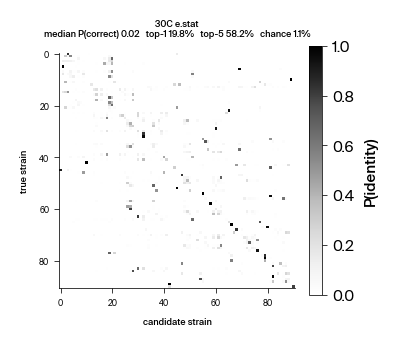

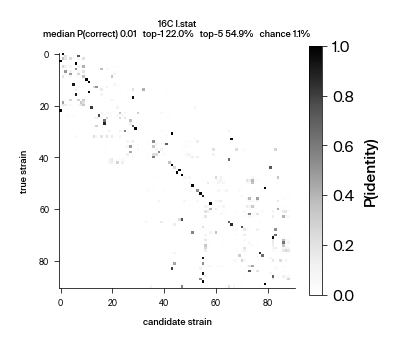

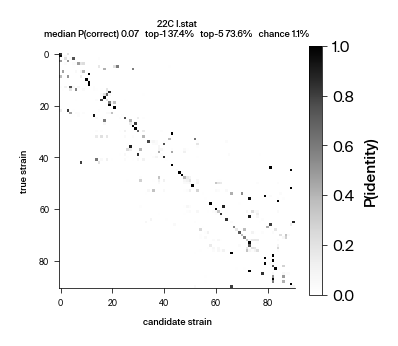

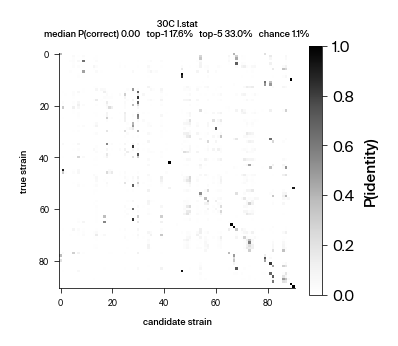

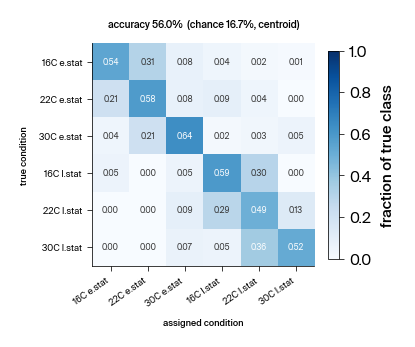

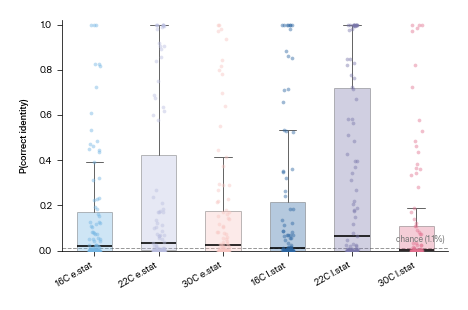

In [22]:
if RUN_SUPPLEMENTAL["strain_identity"]:
    strain_id = cvpp.identify_strains_from_predictions(
        training_data_finite, EXP_CONDITIONS,
        ridge_alpha=RIDGE_ALPHA, n_splits=N_CV_SPLITS, groups=well_groups, random_state=RANDOM_STATE,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
    )
    cvpp.plot_strain_identification(strain_id, EXP_CONDITIONS, CONDITION_TITLES,
                                    save=True, figtitle="strain_identification")

    cond_id = cvpp.identify_condition_from_phenotype(
        training_data_finite, EXP_CONDITIONS, method="centroid",
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
    )
    cvpp.plot_condition_identification(cond_id, CONDITION_TITLES,
                                       save=True, figtitle="condition_identification")

    fig, ax, identity_prob_df = cvpp.plot_identity_probability_distribution(
        strain_id, EXP_CONDITIONS, CONDITION_TITLES, CONDITION_COLORS,
        save=True, figtitle="identity_probability")

## S3 · Interaction structure beyond strain identity: automatic example pairs
Finds strain pairs whose gap in `INTERACTION_FEATURE` changes across `INTERACTION_CONDITIONS` (interaction) and pairs whose gap holds (strain identity), then plots their reaction norms and example cells.

,kind,strain_a,strain_b,min_abs_gap,max_abs_gap,gap_change_snr,closest_condition,farthest_condition
0,interaction,37,94,0.134508,4.730094,83.715528,l_stat_16,l_stat_30
1,interaction,45,94,0.103676,4.426860,53.638153,l_stat_22,l_stat_30
2,interaction,48,94,0.096243,4.290676,57.896674,l_stat_16,l_stat_30
3,interaction,46,47,0.018087,4.175072,59.607037,l_stat_22,l_stat_30
4,interaction,33,94,0.070732,4.041915,39.862378,l_stat_22,l_stat_30
5,interaction,35,94,0.123054,4.073994,57.336853,l_stat_22,l_stat_30
6,interaction,56,59,0.074211,3.876075,47.925366,l_stat_16,l_stat_30
7,interaction,45,46,0.101654,3.796786,41.842396,l_stat_16,l_stat_30
8,interaction,56,60,0.141466,3.759260,42.834266,l_stat_16,l_stat_30
9,interaction,46,48,0.154607,3.660603,42.759091,l_stat_16,l_stat_30


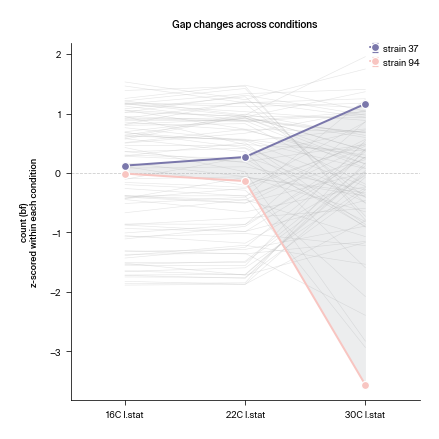

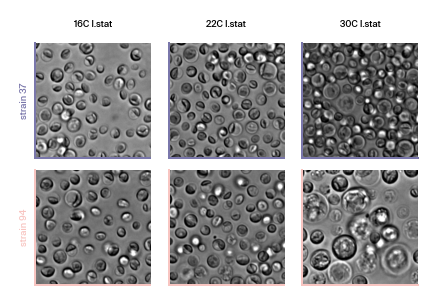

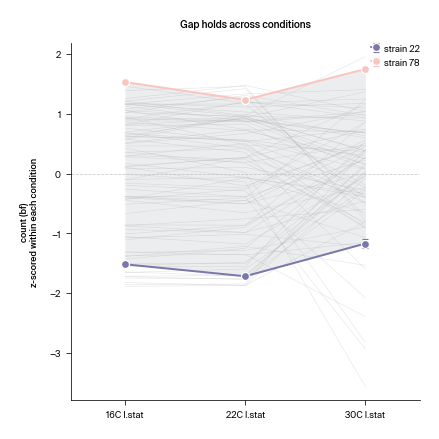

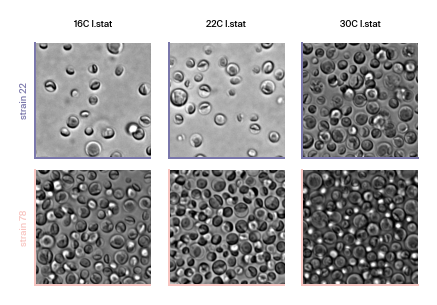

In [23]:
if RUN_SUPPLEMENTAL["interaction_examples"]:
    interaction_labels = [COND_TITLE[c] for c in INTERACTION_CONDITIONS]
    interaction_exp_idx = [EXP_CONDITIONS.index(c) for c in INTERACTION_CONDITIONS]

    pairs = cvpp.find_interaction_example_strains(
        training_data_finite, training_feature_labels,
        feature=INTERACTION_FEATURE, conditions=INTERACTION_CONDITIONS,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
        apart_min=INTERACTION_APART_MIN, together_max=INTERACTION_TOGETHER_MAX,
        min_snr=INTERACTION_MIN_SNR,
    )
    save_table(pairs, "interaction_example_pairs.csv", index=False)
    display(pairs[["kind", "strain_a", "strain_b", "min_abs_gap", "max_abs_gap",
                   "gap_change_snr", "closest_condition", "farthest_condition"]])

    for kind, title, tag in [("interaction", "Gap changes across conditions", "interaction"),
                             ("strain", "Gap holds across conditions", "strain_identity")]:
        subset = pairs[pairs.kind == kind]
        if subset.empty:
            print(f"no {kind} pairs; loosen the thresholds")
            continue
        row = subset.iloc[0]
        cvpp.plot_strain_pair_reaction_norm(
            training_data_finite, training_feature_labels, feature=INTERACTION_FEATURE,
            conditions=INTERACTION_CONDITIONS, strain_a=int(row.strain_a), strain_b=int(row.strain_b),
            condition_labels=interaction_labels, n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
            figsize=(6, 6), title=title, show_population=True, annotate_gaps=True,
            save=True, figtitle=f"reaction_norm_{tag}",
        )
        cvpp.plot_strain_pair_cell_grid(
            zroots, strain_a=int(row.strain_a), strain_b=int(row.strain_b),
            experiment_indices=interaction_exp_idx, condition_labels=interaction_labels,
            channel="BF", fov=EXAMPLE_IMAGE_FOV, n_cells=1, crop=EXAMPLE_IMAGE_CROP,
            save=True, figtitle=f"{tag}_example_cells",
        )

## S4 · Batch effects
1. **Plate position effects:** the fraction of each feature's strain-level variance explained by plate row and column.
2. **Cross-condition gradient consistency:** whether positional gradients repeat across conditions. A repeated gradient could masquerade as strain × environment structure.
3. **WT comparison:** PCA of strain means before and after the between-plate batch correction used in §2.
4. **Wild-type plate as a position-only reference:** see below.


,frac_position
feature,
count (bf),0.883560
count (cy5),0.878293
pixel_intensity (bf),0.794049
pixel_intensity (cy5),0.773326
solidity (bf),0.706122
eccentricity (bf),0.690172
moments_hu-2 (bf),0.603770
axis_major_length (bf),0.538306
perimeter (bf),0.535573


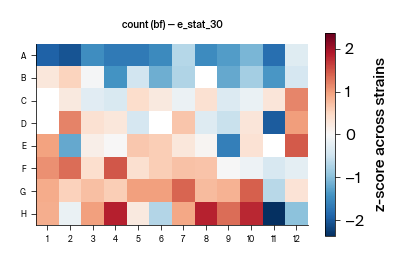

median excess interaction from position: 0.0113


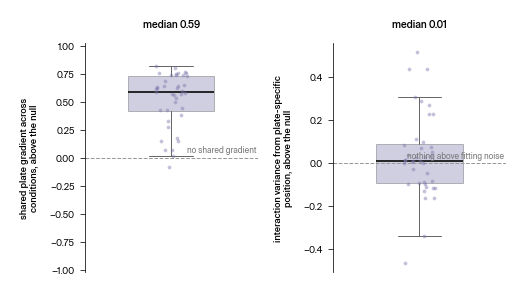

In [54]:
if RUN_SUPPLEMENTAL["batch_effects"]:
    pos = cvpp.plate_position_effects(
        training_data_finite, EXP_CONDITIONS, training_feature_labels,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
        plate_rows=PLATE_ROWS, plate_cols=PLATE_COLS, layout=PLATE_LAYOUT,
    )
    save_table(pos, "plate_position_effects.csv", index=False)
    display(pos.groupby("feature").frac_position.median().sort_values(ascending=False).head(10).to_frame())

    cvpp.plot_plate_heatmap(training_data_finite, PLATE_HEATMAP_CONDITION, PLATE_HEATMAP_FEATURE_INDEX,
                            training_feature_labels, n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
                            plate_rows=PLATE_ROWS, plate_cols=PLATE_COLS, layout=PLATE_LAYOUT,
                            save=True, figtitle=f"plate_heatmap_{PLATE_HEATMAP_CONDITION}")

    grad = cvpp.cross_condition_gradient_consistency(
        training_data_finite, EXP_CONDITIONS, training_feature_labels,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
        plate_rows=PLATE_ROWS, plate_cols=PLATE_COLS, layout=PLATE_LAYOUT, n_null=GRADIENT_N_NULL,
    )
    save_table(grad, "cross_condition_gradient_consistency.csv", index=False)
    print("median excess interaction from position:", round(grad.excess_interaction_from_position.median(), 4))
    cvpp.plot_gradient_consistency(grad, save=True, figtitle="cross_condition_gradient_consistency")


### S4b · Wild-type plate as a position-only reference
Every mutant plate uses the same layout, so a strain and its well position are confounded: a gradient shared by all plates looks exactly like a strain main effect, and the analyses above can't separate the two. The wild-type plate can. All of its wells carry the same genotype, so any row and column structure on it is plate position alone.

Per feature:
* **WT plate, row + column fraction:** the fraction of the WT plate's well-to-well variance taken by additive row and column effects (median polish), minus the same fraction when WT wells are shuffled across positions (`WT_GRADIENT_N_NULL` shuffles). Above zero means the WT plate has a real positional gradient.
* **Mutant strain effect predicted by the WT surface:** the R² of a straight line predicting each mutant strain's main effect (each condition centred, then averaged across conditions) from the WT plate's fitted row + column surface at that well, minus the same R² with a surface fitted to shuffled WT wells. This is the share of apparent strain-to-strain variation that position alone can account for. Significance is a one-sided permutation test against those shuffles, *p* = (1 + shuffles with R² at least the observed) / (1 + `WT_GRADIENT_N_NULL`), with Benjamini–Hochberg correction across features (`q_r2`; threshold `FDR_Q`). In the plot, black ticks mark each feature's 95th percentile of the shuffle null, and colored bars with an asterisk pass correction. `r2_ref_from_wt_surface` repeats this for the mutant plate grown and imaged like the WT plate (22 °C, early stationary).
* `surface_r`: correlation between the WT and mutant fitted surfaces.

Uses the WT matrix from §2 before its position correction. The WT plate was grown and imaged on a different day, so a gradient that changed between runs would make these estimates low rather than high.


,wt_excess_position,wt_position_p,mut_frac_position,surface_r,r2_mut_from_wt_surface,null_r2_95,p_r2,q_r2,r2_ref_from_wt_surface
feature,,,,,,,,,
count (bf),0.571,0.000,0.866,0.753,0.469,0.173,0.000,0.020,0.613
count (cy5),0.585,0.000,0.842,0.747,0.441,0.177,0.001,0.020,0.566
eccentricity (bf),0.467,0.000,0.679,0.731,0.308,0.155,0.004,0.053,0.407
orientation (cy5),0.592,0.000,0.362,0.436,0.120,0.075,0.012,0.114,0.023
inertia_tensor-0-1 (cy5),0.698,0.000,0.264,0.543,0.091,0.068,0.015,0.114,0.001
solidity (bf),0.405,0.000,0.718,0.572,0.217,0.158,0.019,0.114,0.417
inertia_tensor-1-0 (cy5),0.696,0.000,0.264,0.543,0.091,0.068,0.020,0.114,0.001
axis_minor_length (bf),0.752,0.000,0.530,0.474,0.116,0.114,0.048,0.242,0.066
moments_hu-0 (bf),0.295,0.001,0.659,0.460,0.148,0.157,0.057,0.255,0.255


2 of 40 features: mutant strain effect predicted by the WT plate surface beyond chance (BH q < 0.05): ['count (bf)', 'count (cy5)']


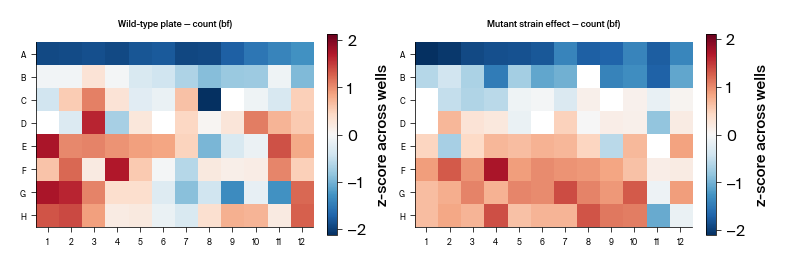

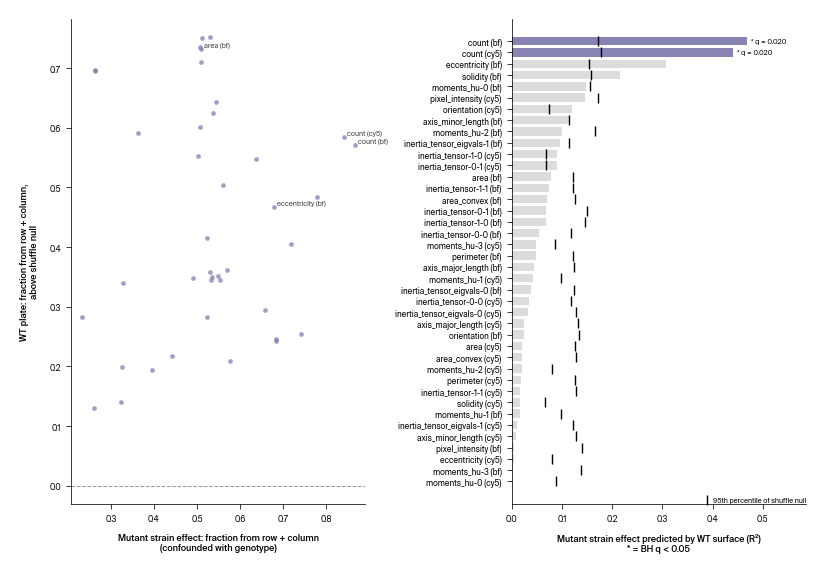

In [55]:
reload(cvpp)
if RUN_SUPPLEMENTAL["batch_effects"]:
    wt_gradient = cvpp.wt_plate_gradient_reference(
        training_data_finite, wt_comparison_data["wt_e22"], EXP_CONDITIONS, training_feature_labels,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids, wt_dead_wells=dead_wells_wt,
        plate_rows=PLATE_ROWS, plate_cols=PLATE_COLS, layout=PLATE_LAYOUT,
        mutant_reference_condition="e_stat_22", n_null=WT_GRADIENT_N_NULL, random_state=RANDOM_STATE,
    )
    save_table(wt_gradient, "wt_plate_gradient_reference.csv", index=False)
    display(wt_gradient.set_index("feature")[[
        "wt_excess_position", "wt_position_p", "mut_frac_position", "surface_r",
        "r2_mut_from_wt_surface", "null_r2_95", "p_r2", "q_r2", "r2_ref_from_wt_surface",
    ]].sort_values("p_r2").round(3))
    passing = wt_gradient.loc[wt_gradient.q_r2 < FDR_Q, "feature"].tolist()
    print(f"{len(passing)} of {len(wt_gradient)} features: mutant strain effect predicted by the WT plate surface "
          f"beyond chance (BH q < {FDR_Q}): {passing}")

    cvpp.plot_wt_vs_mutant_plate(
        training_data_finite, wt_comparison_data["wt_e22"], EXP_CONDITIONS,
        training_feature_labels.index(WT_GRADIENT_PLATE_FEATURE), training_feature_labels,
        n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids, wt_dead_wells=dead_wells_wt,
        plate_rows=PLATE_ROWS, plate_cols=PLATE_COLS, layout=PLATE_LAYOUT,
        save=True, figtitle=f"wt_vs_mutant_plate_{WT_GRADIENT_PLATE_FEATURE.replace(' ', '_').strip('()')}",
    )
    cvpp.plot_wt_gradient_reference(wt_gradient, q_threshold=FDR_Q, save=True, figtitle="wt_plate_gradient_reference")


## S5 · Correlation between features
Pearson correlations between features: first on strain means (pooled across conditions), then on individual cells (up to `FEATURE_CORR_MAX_CELLS_PER_WELL` per well), for each channel. These are read from the raw JSONL features (no Hu log transform).

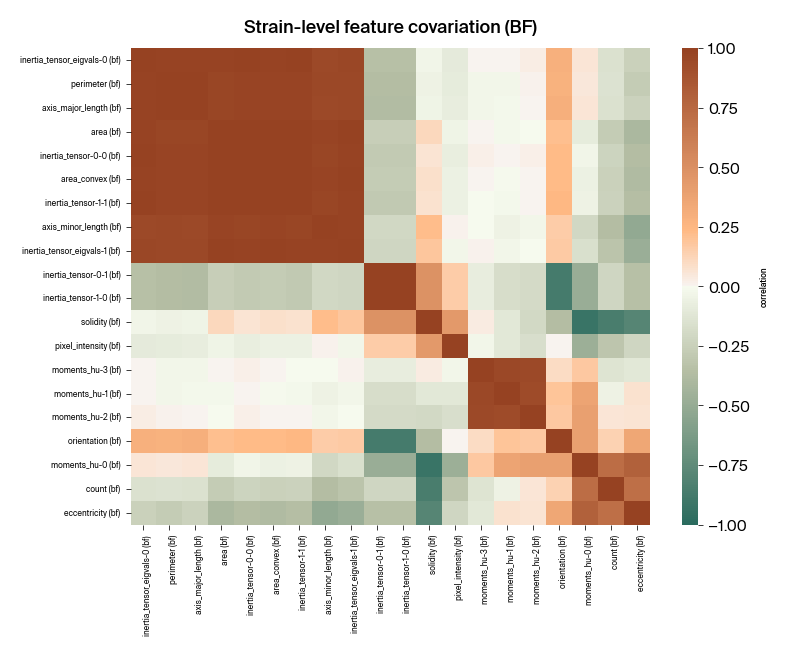

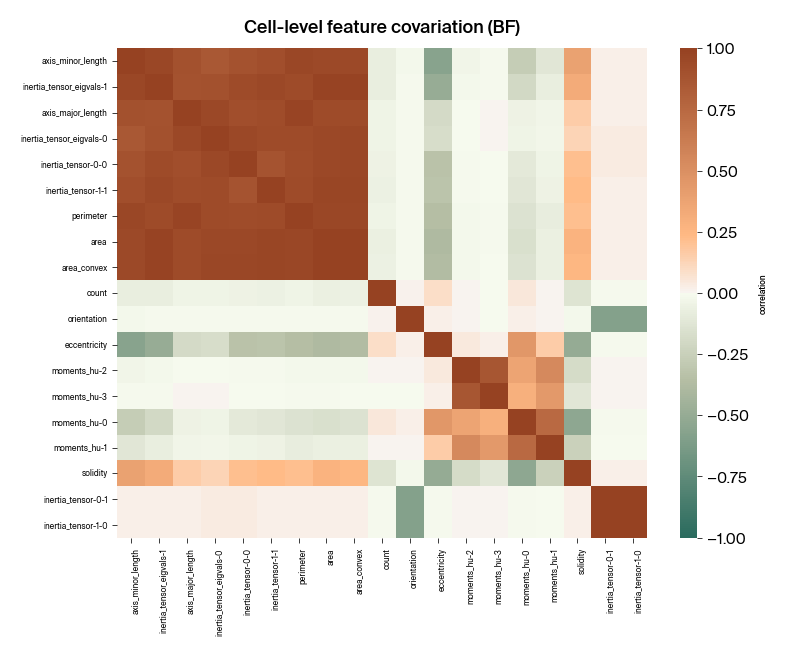

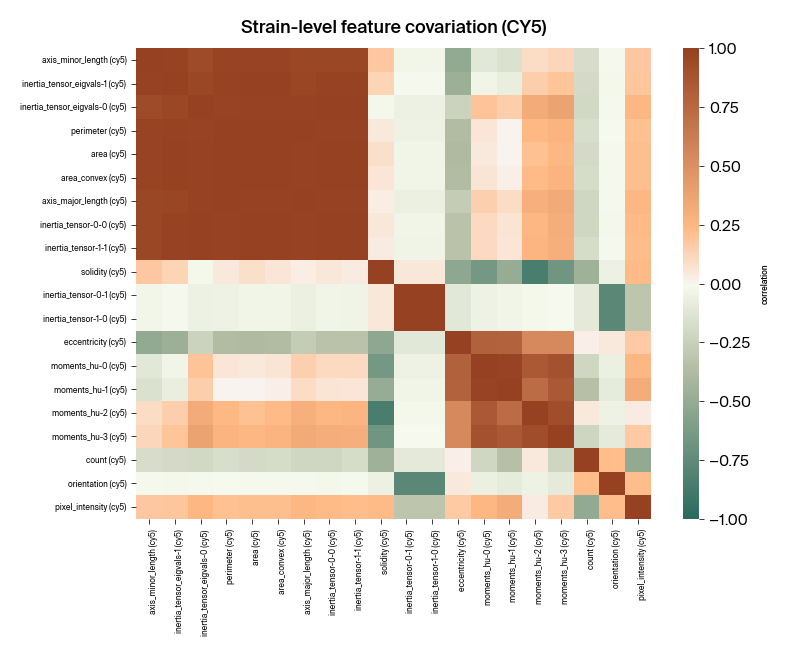

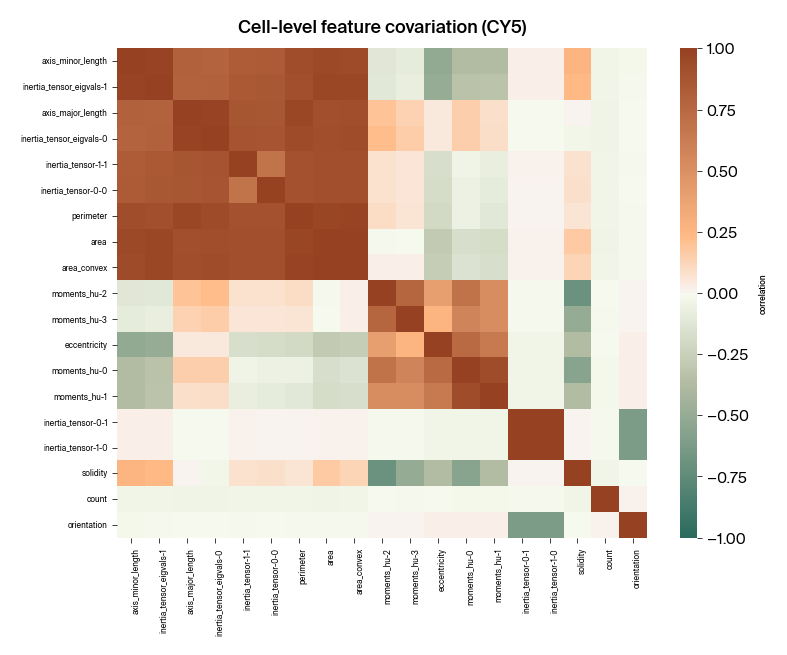

In [25]:
if RUN_SUPPLEMENTAL["feature_correlations"]:
    cond_short = ["e.16C", "e.22C", "e.30C", "l.16C", "l.22C", "l.30C"]
    feature_corr = {}
    for channel in CHANNELS:
        corr_strain, _ = cvpp.compute_feature_covariation_matrix(
            zroots=zroots, channel=channel, exp_conditions=list(range(len(EXP_CONDITIONS))),
            condition_labels=cond_short, n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
            include_pixel_intensity=True, exclude_features=EXCLUDE_FEATURES,
            summary_level="strain", summary_method="mean", correlation_method="pearson",
            return_feature_table=True,
        )
        cvpp.plot_feature_covariation_heatmap(
            corr_strain, figsize=(11, 9), cluster=True, save=True,
            title=f"Strain-level feature covariation ({channel})",
            figtitle=f"feature_covariation_heatmap_{channel.lower()}",
        )
        corr_cell, _ = cvpp.compute_feature_covariation_matrix_cell_level(
            zroots=zroots, exclude_features=EXCLUDE_FEATURES, channel=channel,
            exp_conditions=list(range(len(EXP_CONDITIONS))), condition_labels=cond_short,
            n_wells=N_WELLS, n_fovs=N_FOVS, dead_ids=dead_ids,
            max_cells_per_well=FEATURE_CORR_MAX_CELLS_PER_WELL,
        )
        cvpp.plot_feature_covariation_heatmap(
            corr_cell, figsize=(11, 9), cluster=True, save=True,
            title=f"Cell-level feature covariation ({channel})",
            figtitle=f"feature_covariation_heatmap_cell_level_{channel.lower()}",
        )
        feature_corr[channel] = {"strain": corr_strain, "cell": corr_cell}
        save_table(corr_strain, f"feature_correlation_strain_level_{channel.lower()}.csv")
        save_table(corr_cell, f"feature_correlation_cell_level_{channel.lower()}.csv")